In [1]:
!pip install spektral

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.1/140.1 kB 3.0 MB/s eta 0:00:00


In [1]:
import kagglehub
path = kagglehub.dataset_download("truthisneverlinear/bach-breast-cancer-histology-images")
print("Path to dataset files:", path)

100%|██████████| 12.5G/12.5G [05:36<00:00, 39.8MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/truthisneverlinear/bach-breast-cancer-histology-images/versions/1


Removed existing file/link at: /content/BACH_Dataset
Dataset linked to: /content/BACH_Dataset
Epoch 1/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 69s 563ms/step - accuracy: 0.3319 - loss: 5.1630 - val_accuracy: 0.2625 - val_loss: 5.3000 - learning_rate: 1.0000e-04
Epoch 2/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 181ms/step - accuracy: 0.7764 - loss: 4.0878 - val_accuracy: 0.3375 - val_loss: 4.7964 - learning_rate: 1.0000e-04
Epoch 3/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 180ms/step - accuracy: 0.8854 - loss: 3.7447 - val_accuracy: 0.4875 - val_loss: 4.5221 - learning_rate: 1.0000e-04
Epoch 4/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 185ms/step - accuracy: 0.9887 - loss: 3.5417 - val_accuracy: 0.5500 - val_loss: 4.3153 - learning_rate: 1.0000e-04
Epoch 5/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 183ms/step - accuracy: 0.9878 - loss: 3.4662 - val_accuracy: 0.6625 - val_loss: 4.1586 - learning_rate: 1.0000e-04
Epoch 6/25
20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 181ms/step - accuracy: 0.9945 - loss: 3.4102 - val_accuracy: 0.7125 - val_loss: 4.04

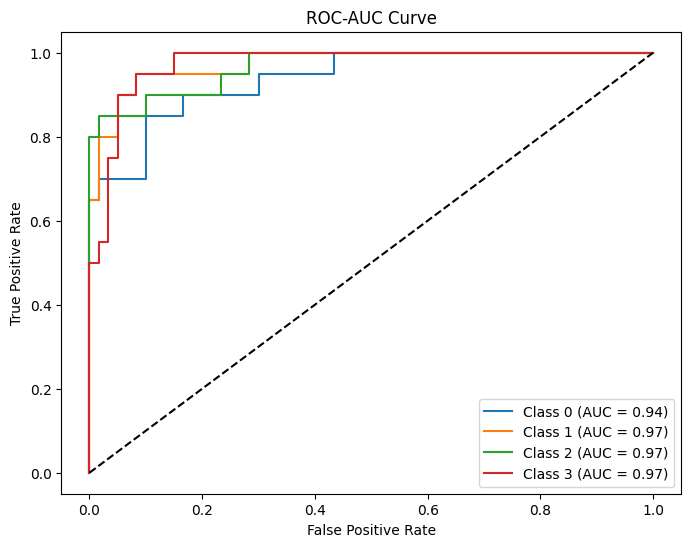

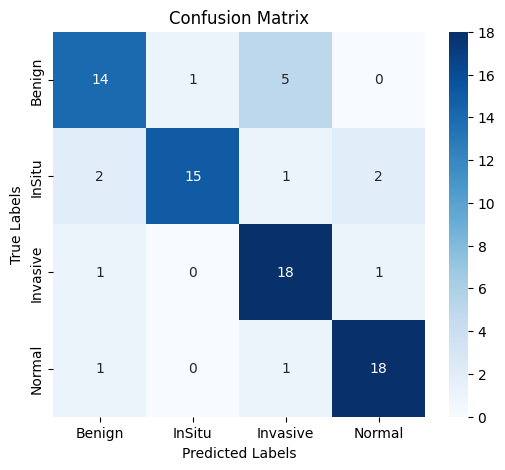

Test Accuracy: 0.8125
Test Precision: 0.8231
Test Recall: 0.8125
Test F1-score: 0.8121


In [6]:
import os
import numpy as np
import cv2
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input, ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.regularizers import l2
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from scipy.sparse import csr_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

# Set seed for reproducibility
def set_seed(seed=42):
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)

set_seed()

source_path = "/root/.cache/kagglehub/datasets/truthisneverlinear/bach-breast-cancer-histology-images/versions/1"
destination_path = "/content/BACH_Dataset"

if os.path.exists(destination_path):
    os.remove(destination_path)  # Remove existing file/link
    print(f"Removed existing file/link at: {destination_path}")

# Now create the symbolic link
os.symlink(source_path, destination_path)
print("Dataset linked to:", destination_path)

# Dataset Path
dataset_path = "/content/BACH_Dataset/ICIAR2018_BACH_Challenge/ICIAR2018_BACH_Challenge/Photos"
img_size = (224, 224)
num_classes = 4

# Label Mapping
label_mapping = {"Benign": 0, "InSitu": 1, "Invasive": 2, "Normal": 3}

# Load and preprocess images
X_images, y_labels = [], []
valid_extensions = (".jpg", ".jpeg", ".png", ".tif", ".tiff")

for label in os.listdir(dataset_path):
    label_path = os.path.join(dataset_path, label)
    if os.path.isdir(label_path) and label in label_mapping:
        for image_id in os.listdir(label_path):
            if not image_id.lower().endswith(valid_extensions):
                continue
            image_path = os.path.join(label_path, image_id)
            image_data = cv2.imread(image_path)
            if image_data is None:
                continue
            image_data = cv2.resize(image_data, img_size)
            image_data = preprocess_input(image_data)
            X_images.append(image_data)
            y_labels.append(label_mapping[label])

X_images = np.array(X_images)
y_labels = np.array(y_labels)
y_labels = to_categorical(y_labels, num_classes=num_classes)

# Graph data
num_nodes = X_images.shape[0]
num_features = 10
X_nodes = np.random.rand(num_nodes, num_nodes, num_features)
adj_matrix = csr_matrix(np.eye(num_nodes))  # Self-connections

# Train-test split
X_train_images, X_val_images, X_train_nodes, X_val_nodes, y_train, y_val = train_test_split(
    X_images, X_nodes, y_labels, test_size=0.2, random_state=42, stratify=y_labels)

adj_train = adj_matrix[:len(X_train_images), :len(X_train_images)]
adj_val = adj_matrix[len(X_train_images):, len(X_train_images):]

# GIN Layer
class CustomGIN(tf.keras.layers.Layer):
    def __init__(self, output_dim):
        super(CustomGIN, self).__init__()
        self.dense = tf.keras.layers.Dense(output_dim, activation="relu", kernel_regularizer=l2(0.01))
        self.eps = self.add_weight(shape=(1,), initializer="zeros", trainable=True)
        self.dropout = tf.keras.layers.Dropout(0.3)

    def call(self, inputs):
        node_features, adjacency_vector = inputs
        adjacency_vector = tf.expand_dims(adjacency_vector, axis=-1)  # Reshape to (batch_size, num_nodes, 1)
        adjacency_matrix = tf.linalg.diag(adjacency_vector[..., 0])  # Convert to (batch_size, num_nodes, num_nodes)

        aggregated_features = (1 + self.eps) * node_features + tf.matmul(adjacency_matrix, node_features)
        x = self.dense(aggregated_features)
        x = self.dropout(x)
        return tf.reduce_mean(x, axis=1)

# Model Definition
def build_updated_model(num_features, num_nodes):
    image_input = tf.keras.layers.Input(shape=(224, 224, 3), name="image_input")
    base_model = ResNet50(weights="imagenet", include_top=False, input_tensor=image_input)
    for layer in base_model.layers[-10:]:  # Unfreeze last 10 layers
        layer.trainable = True
    image_features = tf.keras.layers.GlobalAveragePooling2D()(base_model.output)
    image_features = tf.keras.layers.BatchNormalization()(image_features)

    tabular_input = tf.keras.layers.Input(shape=(num_nodes, num_features), name="tabular_input")
    adj_input = tf.keras.layers.Input(shape=(num_nodes,), name="adj_input")
    gin_output = CustomGIN(output_dim=32)([tabular_input, adj_input])

    combined = tf.keras.layers.Concatenate()([image_features, gin_output])
    combined = tf.keras.layers.Dense(128, activation="relu", kernel_regularizer=l2(0.01))(combined)
    combined = tf.keras.layers.BatchNormalization()(combined)
    combined = tf.keras.layers.Dropout(0.4)(combined)
    combined = tf.keras.layers.Dense(64, activation="relu", kernel_regularizer=l2(0.01))(combined)
    output = tf.keras.layers.Dense(4, activation="softmax")(combined)

    return tf.keras.Model(inputs=[image_input, tabular_input, adj_input], outputs=output)

model = build_updated_model(num_features, X_train_nodes.shape[1])

# Learning rate scheduling
def lr_schedule(epoch):
    if epoch < 10:
        return 1e-4
    elif epoch < 20:
        return 5e-5
    else:
        return 1e-5

lr_callback = tf.keras.callbacks.LearningRateScheduler(lr_schedule)

model.compile(optimizer=tf.keras.optimizers.Adam(),
              loss="categorical_crossentropy", metrics=["accuracy"])

adj_train_dense = adj_train.toarray()
adj_val_dense = adj_val.toarray()
adj_train_fixed = np.zeros((adj_train_dense.shape[0], X_train_nodes.shape[1]))
adj_val_fixed = np.zeros((adj_val_dense.shape[0], X_val_nodes.shape[1]))
adj_train_fixed[:, :adj_train_dense.shape[1]] = adj_train_dense
adj_val_fixed[:, :adj_val_dense.shape[1]] = adj_val_dense

# Train Model
history = model.fit(
    [X_train_images, X_train_nodes, adj_train_fixed], y_train,
    validation_data=([X_val_images, X_val_nodes, adj_val_fixed], y_val),
    epochs=25, batch_size=16, verbose=1, callbacks=[lr_callback]
)

# Evaluate Model
y_pred = model.predict([X_val_images, X_val_nodes, adj_val_fixed])
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_val, axis=1)
y_pred = model.predict([X_val_images, X_val_nodes, adj_val_fixed])
y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(y_val, axis=1)

accuracy = accuracy_score(y_true_classes, y_pred_classes)
precision = precision_score(y_true_classes, y_pred_classes, average="macro")
recall = recall_score(y_true_classes, y_pred_classes, average="macro")
f1 = f1_score(y_true_classes, y_pred_classes, average="macro")

# Compute ROC-AUC for each class
fpr = {}
tpr = {}
roc_auc = {}
for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_val[:, i], y_pred[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot ROC-AUC curves
plt.figure(figsize=(8, 6))
for i in range(num_classes):
    plt.plot(fpr[i], tpr[i], label=f'Class {i} (AUC = {roc_auc[i]:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-AUC Curve')
plt.legend()
plt.show()

# Compute and plot Confusion Matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_mapping.keys(), yticklabels=label_mapping.keys())
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Precision: {precision:.4f}")
print(f"Test Recall: {recall:.4f}")
print(f"Test F1-score: {f1:.4f}")
